# 08 — Municipio de Cochabamba y sus 15 distritos

## Por qué este notebook

El reto local pide cubrir los **15 distritos** del municipio de Cochabamba y también las **áreas periurbanas**, no solo el Parque Nacional Tunari. Hasta el notebook 07 solo mirábamos lo que cae **dentro del parque**, que en el municipio de Cochabamba es apenas el Distrito 13. Aquí se aplica la **misma metodología** al municipio completo (295 km², de los cuales 49 km² están dentro del parque):

- misma grilla de 1 km con el mismo origen (las celdas son comparables con las del parque),
- mismo filtro principal, celdas-día y eventos,
- mismo índice MODIS-equivalente, con el factor del parque (en el municipio MODIS casi no registra nada, así que no se puede calibrar localmente),
- mismas alertas: modelo de conteos (binomial negativa estacional) más el Z-score clásico.

> Una detección no es un incendio confirmado. Los límites de los distritos son de referencia abierta, no oficiales.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
SERIES = ROOT / "DATOS_PROCESADOS" / "series"
FIGURES = ROOT / "DATOS_PROCESADOS" / "figuras"

In [2]:
resumen = json.loads((ROOT / 'DATOS_PROCESADOS' / 'resumen_cbba.json').read_text(encoding='utf-8'))
display(pd.Series(resumen, name='valor').to_frame())

,valor
area_municipio_km2,295.2
area_municipio_dentro_parque_km2,49.0
detecciones,680
detecciones_dentro_parque,201
detecciones_fuera_parque,479
celdas_1km_con_detecciones,177
celdas_fuente_persistente_probable,2
detecciones_en_fuentes_persistentes,113
detecciones_sin_fuentes_persistentes,567
eventos_candidatos,418


## Dónde ocurre la actividad

Dentro del parque cae una tercera parte de las detecciones del municipio; **dos tercios ocurren fuera del parque**, en distritos periurbanos. La «franja periurbana» es un **proxy** de la interfaz urbano-forestal (hasta 2 km fuera del límite del parque): no se usó un modelo de elevación, así que no se delimita la cota 2750 propiamente dicha.

In [3]:
display(pd.read_csv(SERIES / 'cbba_zonas_resumen.csv'))
distritos = pd.read_csv(SERIES / 'cbba_distritos_resumen.csv')
display(distritos.drop(columns='advertencia'))

,zona,detecciones,celdas_1km_distintas,eventos_candidatos,pct_detecciones_municipio
0,Dentro del Parque Tunari,201,45,58,29.6
1,Franja periurbana (≤ 2 km del parque),10,8,10,1.5
2,Resto del municipio,469,125,350,69.0


,distrito,detecciones,celdas_1km_distintas,eventos_candidatos,detecciones_dentro_parque,primer_anio,ultimo_anio,detecciones_en_fuentes_persistentes,detecciones_sin_fuentes_persistentes,pct_detecciones_municipio,detecciones_fuera_parque,mes_pico,indice_medio_anual_2013_2025,anio_pico,alertas_calculadas
0,Distrito 9,217,77,142,0,2006,2026,0,217,31.9,217,9,1.54,2026,True
1,Distrito 13,201,45,58,201,2001,2026,0,201,29.6,0,9,1.41,2019,True
2,Distrito 8,103,11,89,0,2008,2026,54,49,15.1,103,6,0.60,2026,True
3,Distrito 14,48,4,44,0,2012,2026,39,9,7.1,48,11,0.28,2020,False
4,Distrito 4,25,8,24,0,2013,2026,0,25,3.7,25,7,0.19,2019,False
5,Distrito 15,24,12,17,0,2006,2026,0,24,3.5,24,4,0.12,2012,False
6,Distrito 7,22,3,20,0,2012,2026,20,2,3.2,22,10,0.13,2020,False
7,Distrito 5,11,7,10,0,2016,2026,0,11,1.6,11,1,0.07,2022,False
8,Distrito 6,9,4,4,0,2002,2021,0,9,1.3,9,10,0.05,2021,False
9,Distrito 2,6,4,6,0,2009,2024,0,6,0.9,6,6,0.03,2024,False


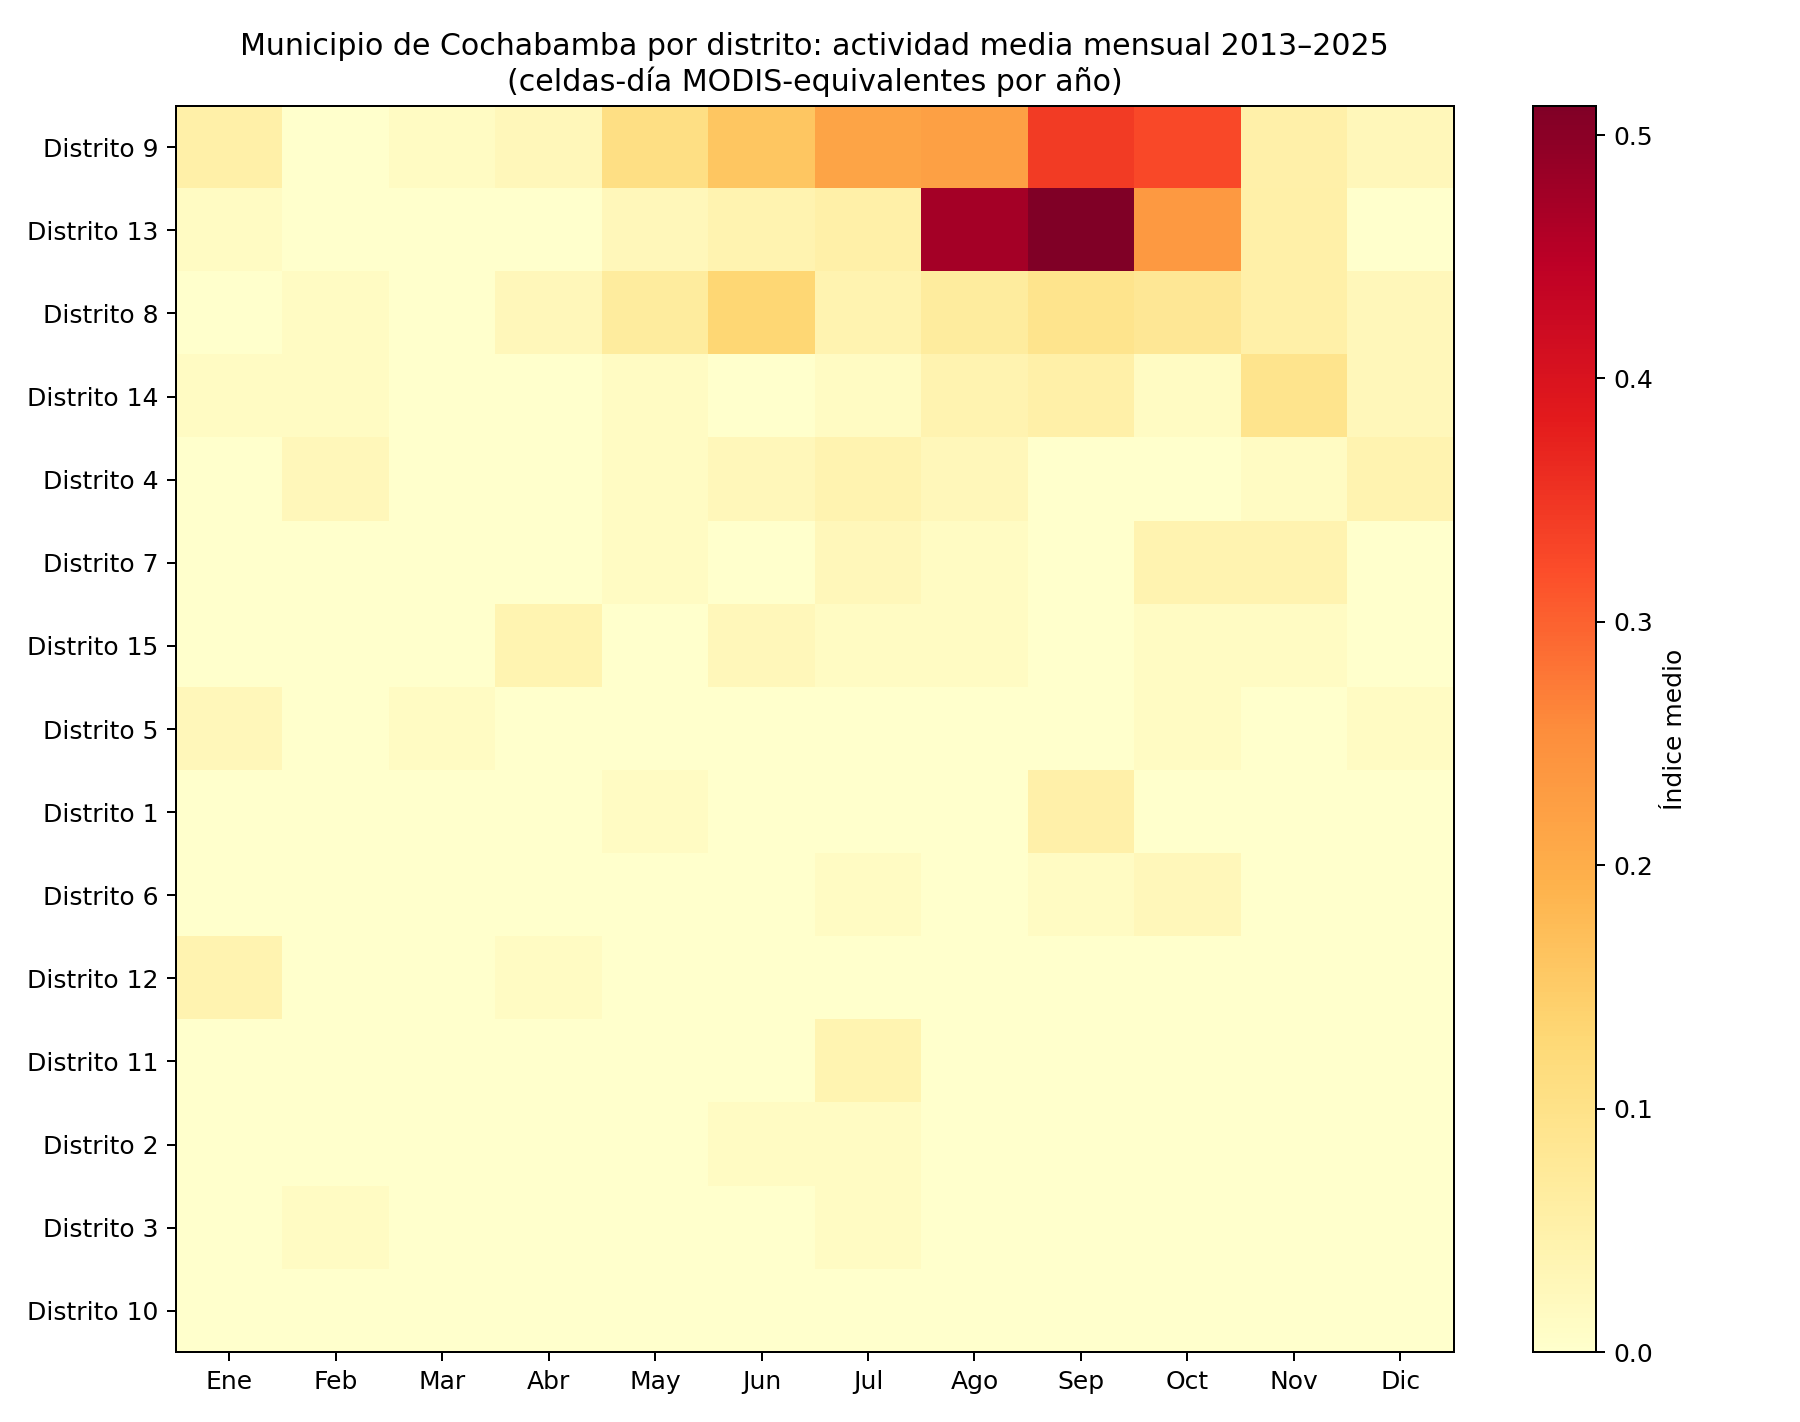

In [4]:
display(Image(filename=str(FIGURES / 'cbba_calendario_distritos.png')))

Los distritos **9, 13 y 8** concentran el 75 % de la actividad: el 13 es el del parque; el 9 y el 8 son periurbanos y **no aparecían en el análisis del parque**. En 11 de los 15 distritos hay menos de 25 detecciones en 25 años: se muestran sus calendarios y conteos, pero **no se calculan alertas** porque el historial es casi todo ceros.

## Calendario mes × año del municipio

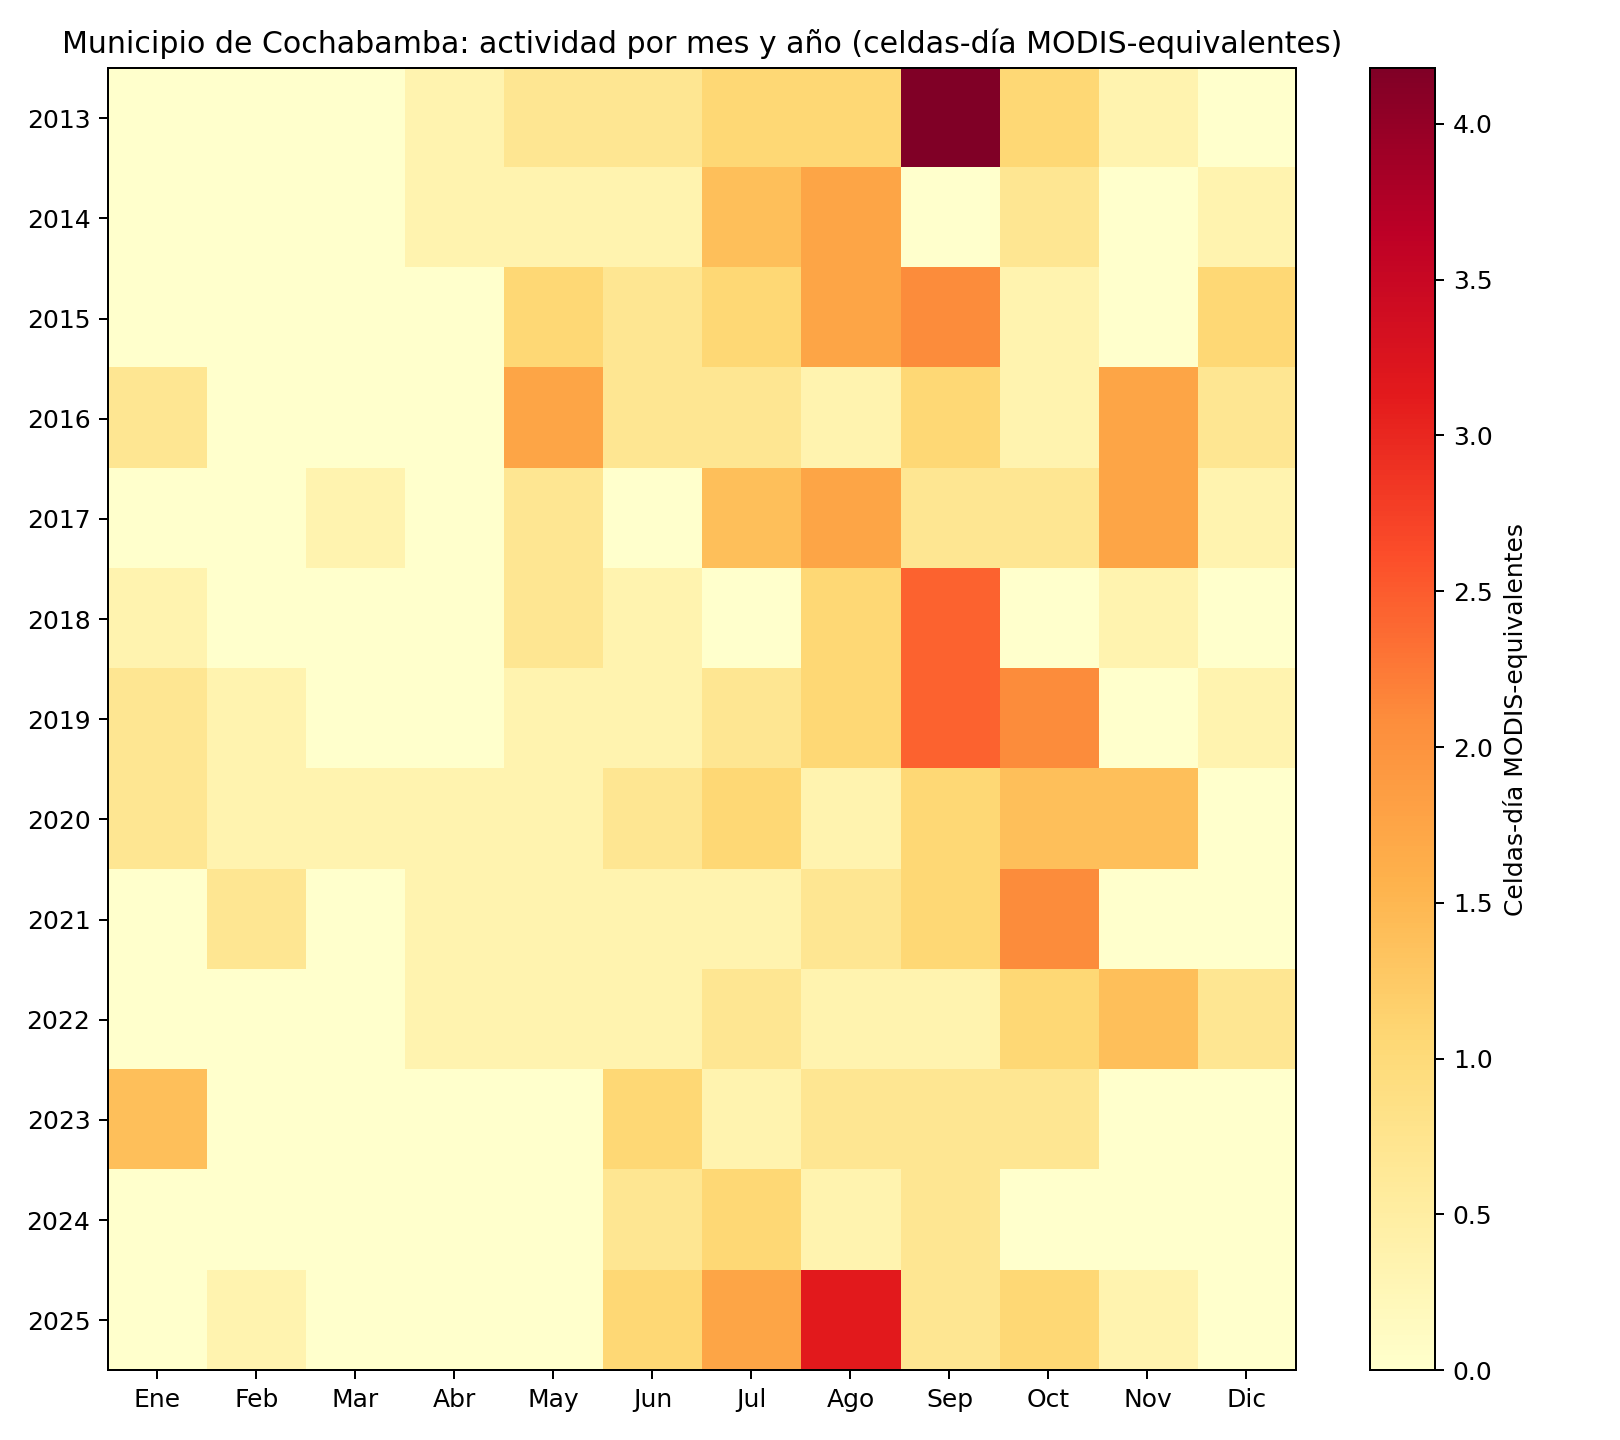

In [5]:
display(Image(filename=str(FIGURES / 'cbba_calendario_mes_anio.png')))

## Recurrencia espacial: ¿en qué sectores se repite?

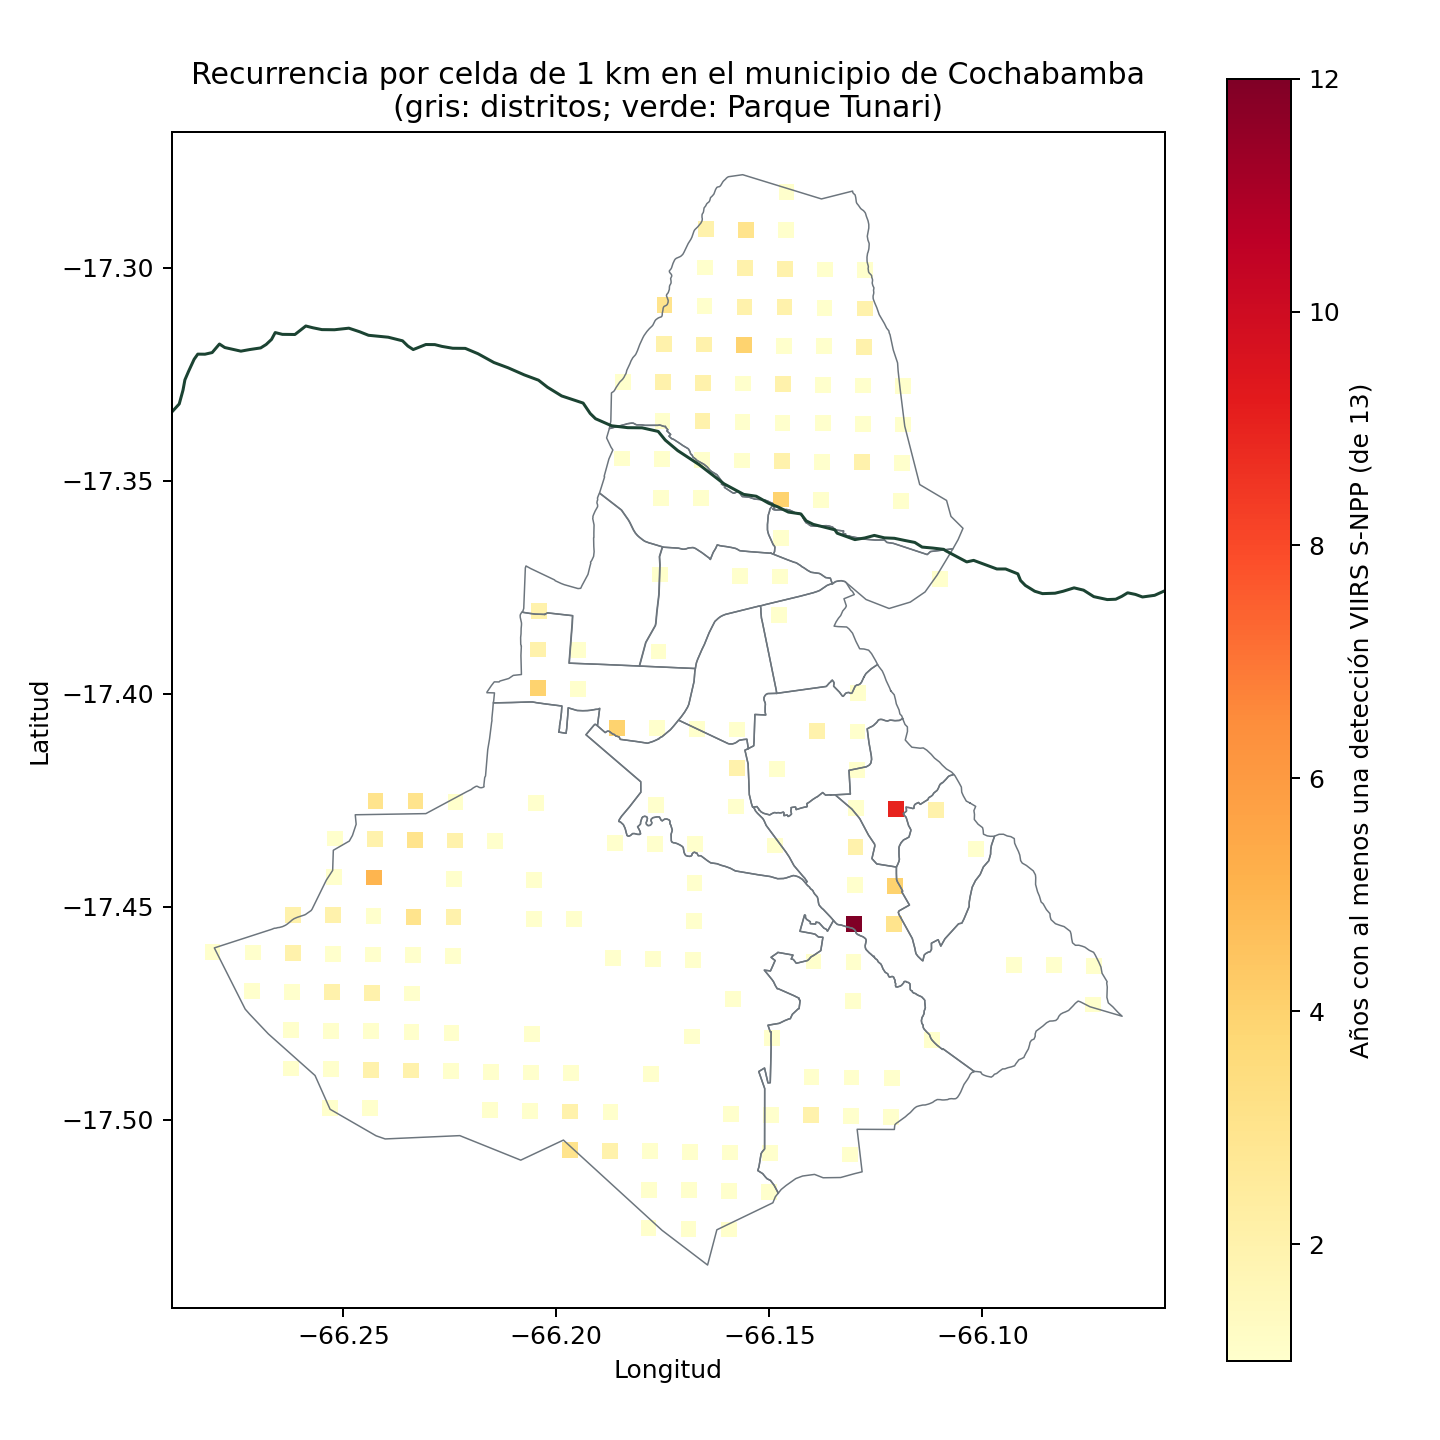

,ranking,cell_id_1km,distrito_principal,detecciones_total,anios_con_fuego_viirs_2013_2025,pct_anios_viirs_2013_2025,mes_pico
0,1,32720_65_12,Distrito 8,54,12,92.3,10
1,2,32720_66_15,Distrito 14,59,9,69.2,11
2,3,32720_53_13,Distrito 9,13,5,38.5,5
3,4,32720_62_27,Distrito 13,19,4,30.8,10
4,5,32720_66_13,Distrito 8,15,4,30.8,11
5,6,32720_59_17,Distrito 4,10,4,30.8,6
6,7,32720_63_23,Distrito 13,8,4,30.8,8
7,8,32720_57_18,Distrito 4,5,4,30.8,2
8,9,32720_66_12,Distrito 8,23,3,23.1,9
9,10,32720_58_6,Distrito 9,11,3,23.1,10


In [6]:
display(Image(filename=str(FIGURES / 'cbba_recurrencia_por_celda.png')))
celdas = pd.read_csv(SERIES / 'cbba_recurrencia_por_celda.csv')
display(celdas.head(10)[['ranking','cell_id_1km','distrito_principal','detecciones_total','anios_con_fuego_viirs_2013_2025','pct_anios_viirs_2013_2025','mes_pico']])

## Posibles fuentes persistentes (no son incendios)

Dos celdas del sureste (Distritos 8, 14 y 7) tienen detecciones en 12 y 9 de los 13 años, de noche, en todos los meses y con potencia muy baja (mediana de 0,5 MW). Ese patrón **no parece el de un incendio de vegetación**; es compatible con una **fuente fija de calor** (por ejemplo un botadero, hornos u otra actividad industrial). **No se puede confirmar con estos datos**: hay que verificarlo con imágenes o con conocimiento local. Se marcan con la regla «detecciones en al menos 8 de 13 años» (hay un salto claro: la tercera celda tiene 5 años) y se muestran los resultados con y sin ellas. Las alertas del municipio no cambian al excluirlas, porque una fuente constante no produce meses anómalos.

In [7]:
celdas['fuente_persistente_probable'] = celdas['fuente_persistente_probable'].astype(bool)
display(celdas[celdas['fuente_persistente_probable']][['cell_id_1km','distrito_principal','lon_centro','lat_centro','detecciones_total','anios_con_fuego_viirs_2013_2025','mes_pico']])
display(distritos[['distrito','detecciones','detecciones_en_fuentes_persistentes','detecciones_sin_fuentes_persistentes']].head(8))

,cell_id_1km,distrito_principal,lon_centro,lat_centro,detecciones_total,anios_con_fuego_viirs_2013_2025,mes_pico
0,32720_65_12,Distrito 8,-66.13008,-17.45395,54,12,10
1,32720_66_15,Distrito 14,-66.12022,-17.42702,59,9,11


,distrito,detecciones,detecciones_en_fuentes_persistentes,detecciones_sin_fuentes_persistentes
0,Distrito 9,217,0,217
1,Distrito 13,201,0,201
2,Distrito 8,103,54,49
3,Distrito 14,48,39,9
4,Distrito 4,25,0,25
5,Distrito 15,24,0,24
6,Distrito 7,22,20,2
7,Distrito 5,11,0,11


## Puntos calientes espaciales (Getis-Ord Gi*)

Mismo estadístico que en el parque, **sin las celdas de posible fuente persistente**. Muestra los conglomerados de celdas vecinas con más actividad de la esperable por azar (FDR 5 %).

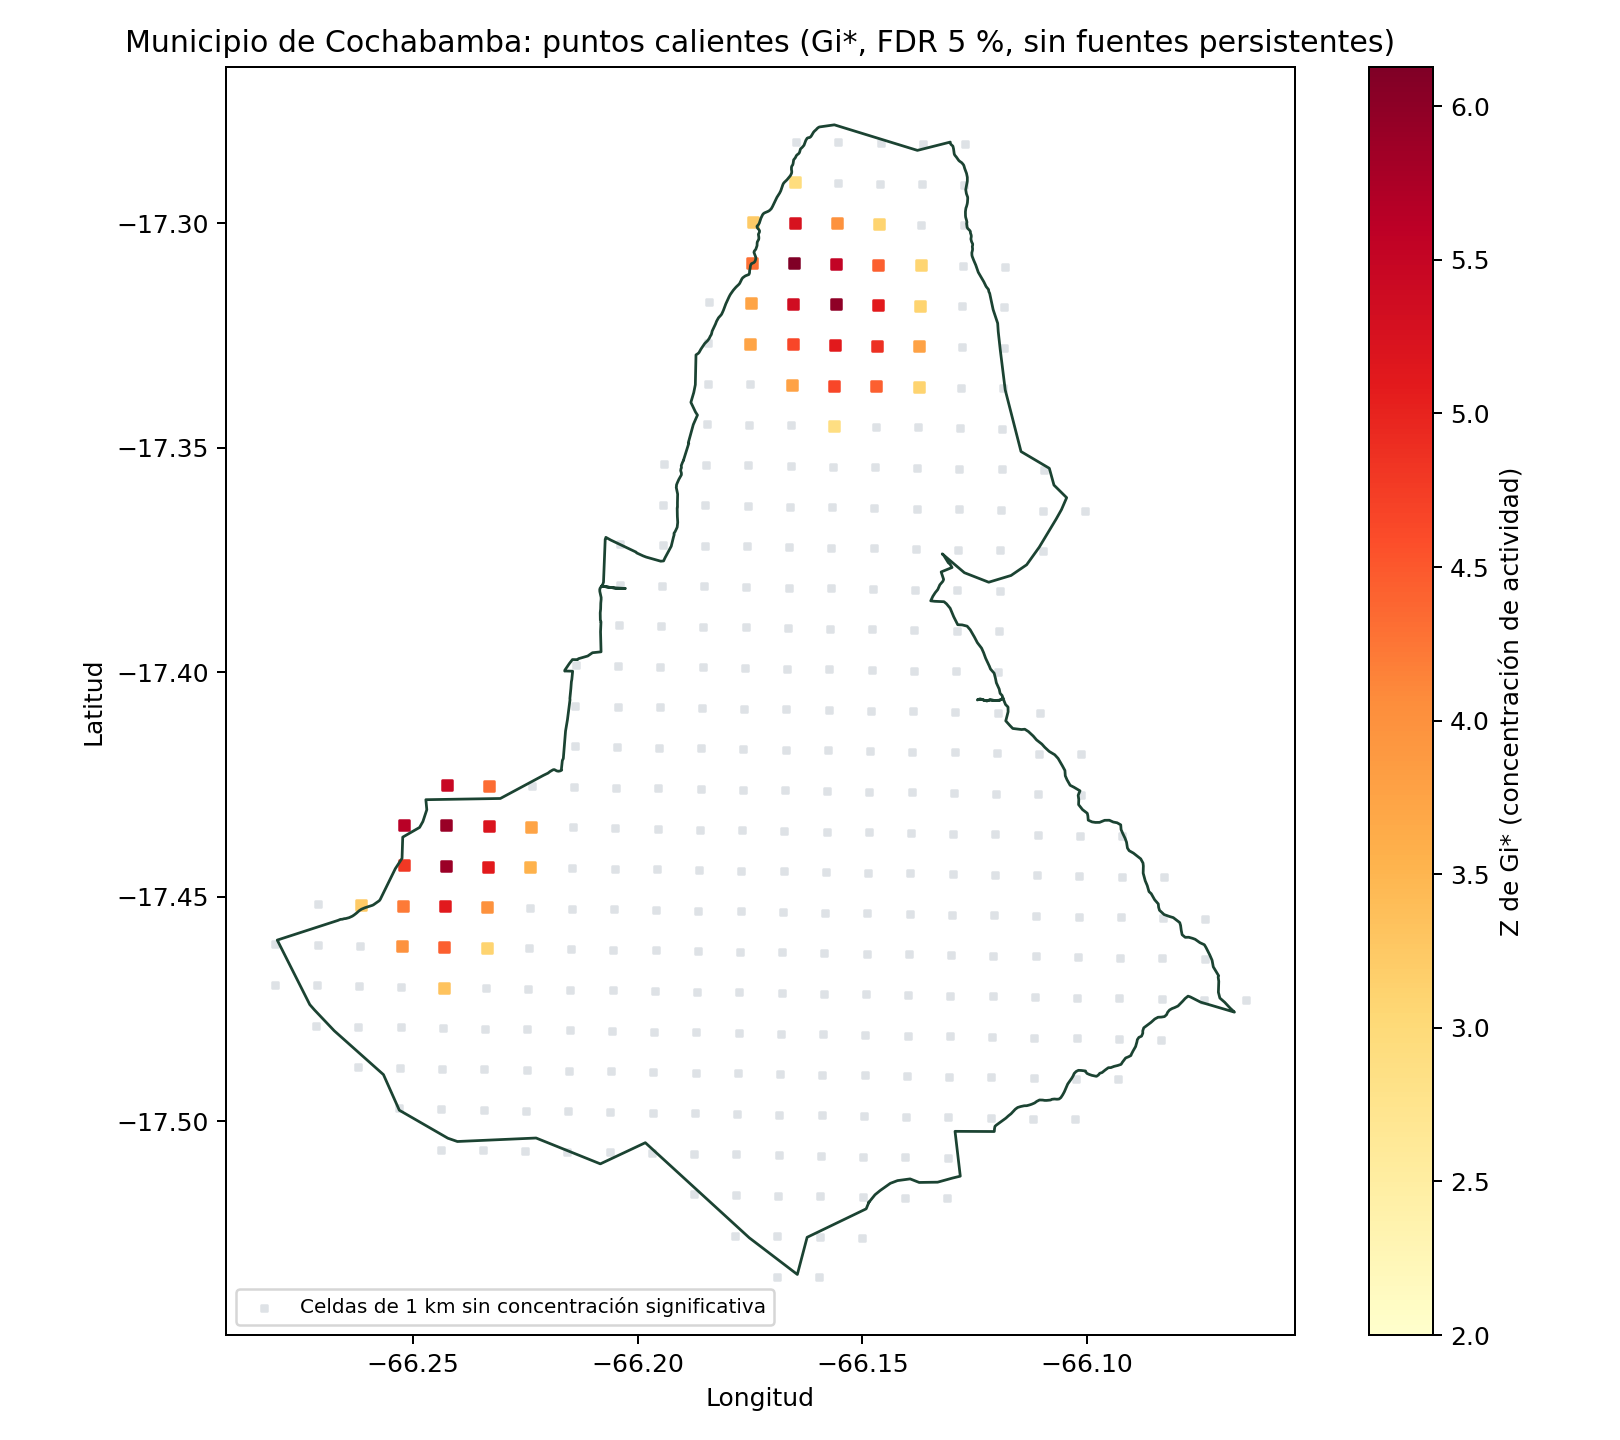

,conglomerado,celdas_1km,celdas_dia_viirs,z_maximo,distrito_principal,lon_centro,lat_centro
0,1,25,43.0,6.13,Distrito 13,-66.16,-17.32
1,0,18,35.0,5.91,Distrito 9,-66.24,-17.45


In [8]:
display(Image(filename=str(FIGURES / 'cbba_puntos_calientes_gi.png')))
display(pd.read_csv(SERIES / 'cbba_conglomerados_gi.csv').drop(columns='advertencia').round(2))

## Anomalías y alertas

Se calculan para el **municipio completo** y para los distritos con al menos 80 detecciones (9, 13 y 8). Cada mes trae: el **Z-score clásico** que menciona el reto (cuántas desviaciones está sobre la media del mismo mes de años anteriores), la **probabilidad de exceso** del modelo de conteos, la **lectura en palabras** y cuántas **veces la mediana histórica** es. El **nivel** de alerta sale de la probabilidad (vigilancia p ≤ 0,10; candidata p ≤ 0,05; muy alta p ≤ 0,01), porque el Z-score por sí solo estaba mal calibrado (ver notebook 06).

In [9]:
al = pd.read_csv(SERIES / 'cbba_alertas_mensuales.csv', parse_dates=['mes_bo'])
marca = al['nivel_alerta'].isin(['elevada', 'alta', 'muy_alta'])
display(al[marca][['area','mes_bo','celdas_dia_base','veces_mediana_historica','z_score','probabilidad_exceso','lectura_modelo','nivel_alerta']].round(3))
ev = al[~al['nivel_alerta'].isin(['sin_baseline','mes_incompleto'])]
display(ev.groupby('area')['nivel_alerta'].value_counts().unstack().fillna(0).astype(int))

,area,mes_bo,celdas_dia_base,veces_mediana_historica,z_score,probabilidad_exceso,lectura_modelo,nivel_alerta
104,Municipio de Cochabamba,2009-09-01,4,NaN,4.000,0.007,Extremadamente inusual: un mes así o más alto ...,muy_alta
115,Municipio de Cochabamba,2010-08-01,3,NaN,2.556,0.053,Inusual: un mes así o más alto ocurre en el 10...,elevada
225,Municipio de Cochabamba,2019-10-01,6,3.0,3.080,0.017,Muy inusual: un mes así o más alto ocurre en e...,alta
249,Municipio de Cochabamba,2021-10-01,6,3.0,1.834,0.055,Inusual: un mes así o más alto ocurre en el 10...,elevada
295,Municipio de Cochabamba,2025-08-01,9,3.0,3.673,0.012,Muy inusual: un mes así o más alto ocurre en e...,alta
309,Municipio de Cochabamba,2026-10-01,6,2.4,1.762,0.080,Inusual: un mes así o más alto ocurre en el 10...,elevada
414,Municipio de Cochabamba (sin fuentes persisten...,2009-09-01,4,NaN,4.000,0.007,Extremadamente inusual: un mes así o más alto ...,muy_alta
425,Municipio de Cochabamba (sin fuentes persisten...,2010-08-01,3,NaN,2.556,0.053,Inusual: un mes así o más alto ocurre en el 10...,elevada
535,Municipio de Cochabamba (sin fuentes persisten...,2019-10-01,6,6.0,3.416,0.006,Extremadamente inusual: un mes así o más alto ...,muy_alta
559,Municipio de Cochabamba (sin fuentes persisten...,2021-10-01,6,3.0,1.862,0.033,Muy inusual: un mes así o más alto ocurre en e...,alta


nivel_alerta,alta,elevada,muy_alta,normal
area,,,,
Distrito 13,1,0,2,187
Distrito 8,0,0,0,190
Distrito 9,1,2,0,187
Municipio de Cochabamba,2,3,1,184
Municipio de Cochabamba (sin fuentes persistentes),2,1,3,184


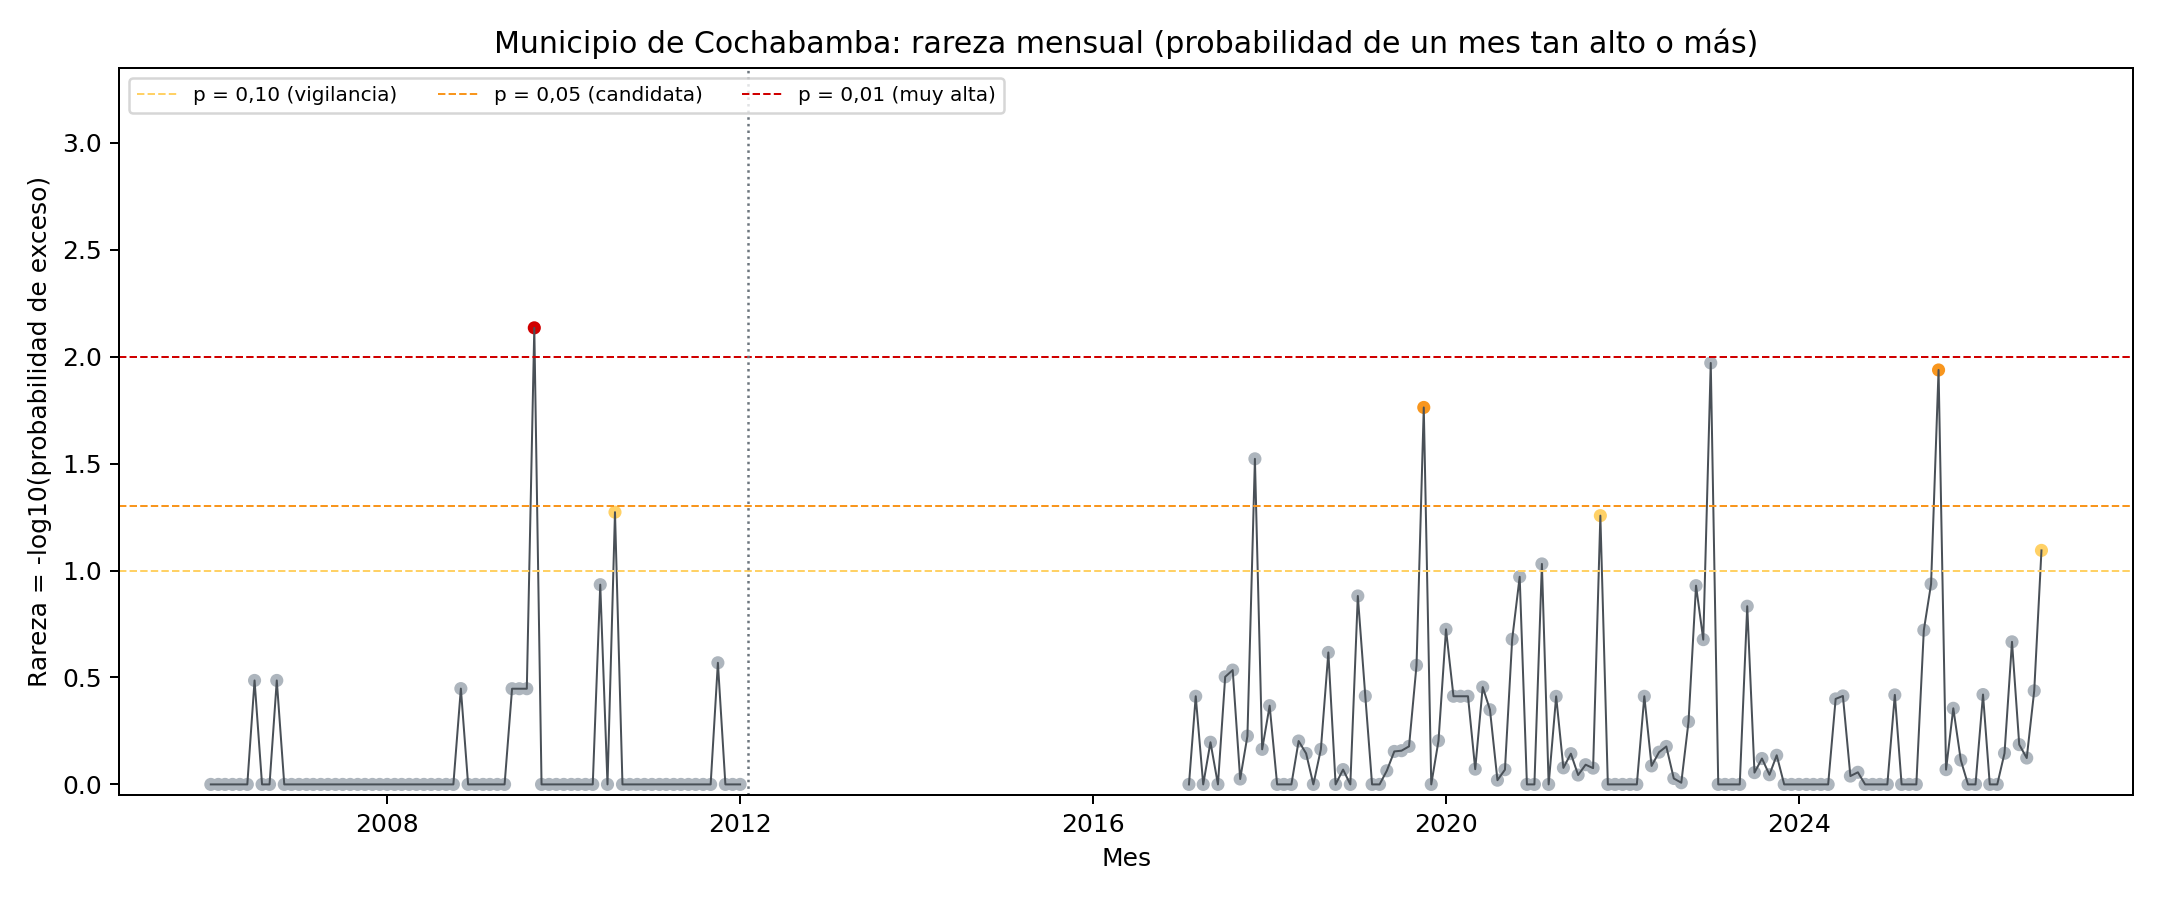

In [10]:
display(Image(filename=str(FIGURES / 'cbba_anomalias_y_alertas.png')))

## Límites y precauciones

- Pocos datos: 607 detecciones en 25 años en todo el municipio; por distrito, aún menos. Las alertas por distrito son **muy poco fiables** y solo se calculan donde hay datos.
- Los distritos son una capa abierta, **no la cartografía oficial del GAMC**. Hay que reemplazarla antes de un uso institucional.
- Un mes en «normal» no descarta un incendio local; un mes en alerta no lo confirma.
- Faltan los datos de 2026 y la validación con coordenadas de incendios reales.